# Ability of Gaussian process regression to estimate data noise-level: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/gaussian_process/plot_gpr_noisy.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/gaussian_process/plot_gpr_noisy.html)).

**Scenario:** 20 noisy samples of `0.5 + sin(3x)` on `[0, 5]` (`RandomState(0)` inputs, `RandomState(1)` noise with
std 0.3). The kernel `1.0 * RBF(length_scale, (1e-2, 1e3)) + WhiteKernel(noise_level, (1e-10, 1e1))` with `alpha=0.0` is
fitted from two initial points: `(10, 1)` reaches the high-noise solution and `(0.1, 1e-2)` the low-noise solution.
The example then evaluates `log_marginal_likelihood(theta=log([0.36, scale, noise]))` on an 80 x 80 grid. Finally
`n_restarts_optimizer=10, random_state=0` lets the restarts find the better optimum.

**Adaptations:** typed kernel constructors (`Bounds(lo, hi)`), `PredictionResult` from `predict(..., return_std=True)`
and a `LikelihoodResult` (`.value`) from `log_marginal_likelihood`, all documented family adaptations. The four
figures are kept, but each sklearn/Moxie pair shares one smaller (dpi 60) row.

**Determinism:** deterministic. The data is seeded, and restarts draw `rng.uniform(bounds[:, 0], bounds[:, 1])` from
`RandomState(0)`, which Moxie reproduces with the same MT19937 stream. L-BFGS-B iterates agree only to optimizer resolution because
floating-point summation order differs. Optimized quantities therefore get optimizer-level tolerances. The likelihood grid uses
fixed hyperparameters and is compared tightly.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("gaussian_process/plot_gpr_noisy")

## 1. scikit-learn (Python reference)

/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


high_noise: Initial: 1**2 * RBF(length_scale=10) + WhiteKernel(noise_level=1)
  Optimum: 0.763**2 * RBF(length_scale=1e+03) + WhiteKernel(noise_level=0.525)
  Log-Marginal-Likelihood: -23.499266455424188
low_noise: Initial: 1**2 * RBF(length_scale=0.1) + WhiteKernel(noise_level=0.01)
  Optimum: 1.05**2 * RBF(length_scale=0.569) + WhiteKernel(noise_level=0.134)
  Log-Marginal-Likelihood: -18.429732528984054
restarts: Initial: 1**2 * RBF(length_scale=10) + WhiteKernel(noise_level=1)
  Optimum: 1.05**2 * RBF(length_scale=0.569) + WhiteKernel(noise_level=0.134)
  Log-Marginal-Likelihood: -18.429732528970845


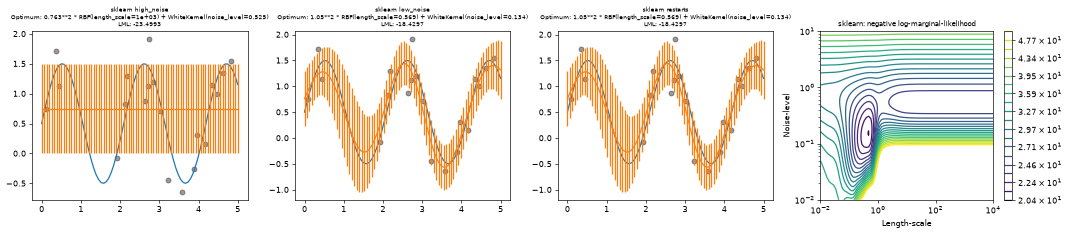

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel


def target_generator(X, add_noise=False):
    target = 0.5 + np.sin(3 * X)
    if add_noise:
        rng = np.random.RandomState(1)
        target += rng.normal(0, 0.3, size=target.shape)
    return target.squeeze()


X = np.linspace(0, 5, num=80).reshape(-1, 1)
y = target_generator(X, add_noise=False)
rng = np.random.RandomState(0)
X_train = rng.uniform(0, 5, size=20).reshape(-1, 1)
y_train = target_generator(X_train, add_noise=True)

runs = {}
for name, (ls, noise, extra) in {"high_noise": (1e1, 1, {}), "low_noise": (1e-1, 1e-2, {}),
                                 "restarts": (1e1, 1, {"n_restarts_optimizer": 10, "random_state": 0})}.items():
    kernel = 1.0 * RBF(length_scale=ls, length_scale_bounds=(1e-2, 1e3)) + WhiteKernel(
        noise_level=noise, noise_level_bounds=(1e-10, 1e1))
    gpr = GaussianProcessRegressor(kernel=kernel, alpha=0.0, **extra)
    gpr.fit(X_train, y_train)
    y_mean, y_std = gpr.predict(X, return_std=True)
    runs[name] = dict(gpr=gpr, mean=y_mean, std=y_std, theta=gpr.kernel_.theta, kernel_=repr(gpr.kernel_),
                      lml=gpr.log_marginal_likelihood(gpr.kernel_.theta), title=f"Initial: {kernel}")
    print(f"{name}: Initial: {kernel}\n  Optimum: {gpr.kernel_}\n  Log-Marginal-Likelihood: {runs[name]['lml']}")

# Likelihood landscape, evaluated on the low-noise model exactly as the example does.
gpr = runs["low_noise"]["gpr"]
length_scale = np.logspace(-2, 4, num=80)
noise_level = np.logspace(-2, 1, num=80)
length_scale_grid, noise_level_grid = np.meshgrid(length_scale, noise_level)
log_marginal_likelihood = [
    gpr.log_marginal_likelihood(theta=np.log([0.36, scale, noise]))
    for scale, noise in zip(length_scale_grid.ravel(), noise_level_grid.ravel())
]
log_marginal_likelihood = np.reshape(log_marginal_likelihood, noise_level_grid.shape)


def plot_runs(results, grid, label):
    fig, axs = plt.subplots(1, 4, figsize=(18, 4), dpi=60)
    for ax, name in zip(axs, ("high_noise", "low_noise", "restarts")):
        r = results[name]
        ax.plot(X, y, label="Expected signal")
        ax.scatter(x=X_train[:, 0], y=y_train, color="black", alpha=0.4, label="Observations")
        ax.errorbar(X, r["mean"], r["std"], label="Posterior mean ± std")
        ax.set_title(f"{label} {name}\nOptimum: {r['kernel_']}\nLML: {r['lml']:.4f}", fontsize=7)
    vmin, vmax = (-grid).min(), 50
    level = np.around(np.logspace(np.log10(vmin), np.log10(vmax), num=20), decimals=1)
    cs = axs[3].contour(length_scale_grid, noise_level_grid, -grid, levels=level, norm=LogNorm(vmin=vmin, vmax=vmax))
    fig.colorbar(cs, ax=axs[3])
    axs[3].set_xscale("log"); axs[3].set_yscale("log")
    axs[3].set_xlabel("Length-scale"); axs[3].set_ylabel("Noise-level")
    axs[3].set_title(f"{label}: negative log-marginal-likelihood", fontsize=8)
    plt.tight_layout()
    plt.show()


plot_runs(runs, log_marginal_likelihood, "sklearn")
nb.share(X=X, X_train=X_train, y_train=y_train,
         grid_theta=np.array([np.log([0.36, s, n]) for s, n in zip(length_scale_grid.ravel(), noise_level_grid.ravel())]))

## 2. Moxie (native Mojo)

Fitting, prediction and the likelihood grid run in Mojo; Python only supplies the data.

In [3]:
%%mojo noisy
from numojo import Shape, zeros
from moxie.gaussian_process import GaussianProcessRegressor
from moxie.gaussian_process.kernels import Bounds, Kernel, RBF, WhiteKernel
from moxie_nb_io import load, save, save_floats, save_strings


def kernel(length_scale: Float64, noise: Float64) -> Kernel:
    return 1.0 * RBF(length_scale, Bounds(1e-2, 1e3)) + WhiteKernel(noise, Bounds(1e-10, 1e1))


def main() raises:
    var X = load("X")
    var X_train = load("X_train")
    var y_train = load("y_train")
    var names = ["high_noise", "low_noise", "restarts"]
    var reprs = List[String]()
    var lml = List[Float64]()
    var grid = List[Float64]()
    for run in range(3):
        var gpr = GaussianProcessRegressor(kernel(1e1, 1.0), alpha=0.0)
        if run == 1:
            gpr = GaussianProcessRegressor(kernel(1e-1, 1e-2), alpha=0.0)
        elif run == 2:
            gpr = GaussianProcessRegressor(kernel(1e1, 1.0), alpha=0.0, n_restarts_optimizer=10, random_state=0)
        _ = gpr.fit(X_train, y_train)
        var result = gpr.predict(X, return_std=True)
        save("mean_" + names[run], result.mean)
        save("std_" + names[run], result.std.value())
        save("theta_" + names[run], gpr.kernel_.theta())
        reprs.append(String(gpr.kernel_))
        lml.append(gpr.log_marginal_likelihood(gpr.kernel_.theta()).value)
        print(String(t"{names[run]}: Optimum: {gpr.kernel_}  Log-Marginal-Likelihood: {lml[run]}"))
        if run == 1:
            # sklearn's np.log([0.36, scale, noise]) rows, shared so both sides use identical theta.
            var thetas = load("grid_theta")
            for i in range(thetas.shape[0]):
                var theta = zeros[DType.float64](Shape(3))
                for j in range(3):
                    theta.unsafe_set(j, thetas.item(i, j))
                grid.append(gpr.log_marginal_likelihood(theta^).value)
    save_strings("kernel_repr", reprs)
    save_floats("lml", lml)
    save_floats("grid", grid)

high_noise: Optimum: 0.763**2 * RBF(length_scale=1e+03) + WhiteKernel(noise_level=0.525)  Log-Marginal-Likelihood: -23.49926645542419
low_noise: Optimum: 1.05**2 * RBF(length_scale=0.569) + WhiteKernel(noise_level=0.134)  Log-Marginal-Likelihood: -18.42973252898406
restarts: Optimum: 1.05**2 * RBF(length_scale=0.569) + WhiteKernel(noise_level=0.134)  Log-Marginal-Likelihood: -18.429732528970842


## 3. Side by side and parity

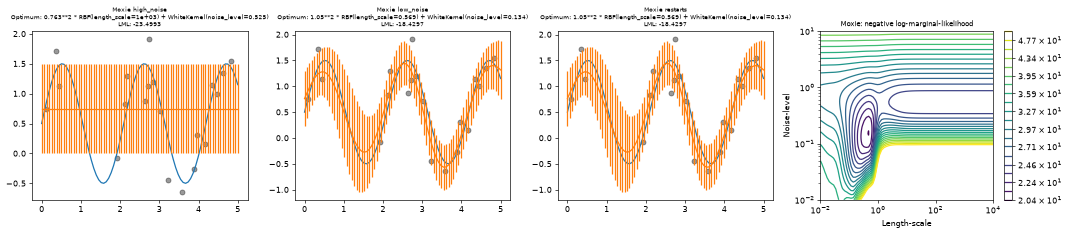

True

In [4]:
mx = nb.results["noisy"]
names = ("high_noise", "low_noise", "restarts")
plot_runs({n: dict(mean=mx[f"mean_{n}"], std=mx[f"std_{n}"], kernel_=mx["kernel_repr"][i], lml=mx["lml"][i])
           for i, n in enumerate(names)}, mx["grid"].reshape(noise_level_grid.shape), "Moxie")
moxie_nb.side_by_side(sklearn=np.array([runs[n]["kernel_"] for n in names]), moxie=mx["kernel_repr"])
OPT = ("same SciPy-faithful L-BFGS-B from the same start; only floating-point summation order differs "
       "(observed agreement ~1e-14; 1e-8 leaves margin for flatter surfaces)")
for i, n in enumerate(names):
    r = runs[n]
    nb.compare(f"{n}: kernel_.theta", r["theta"], mx[f"theta_{n}"], rtol=1e-8, atol=1e-8, reason=OPT)
    nb.compare(f"{n}: log_marginal_likelihood(kernel_.theta)", r["lml"], mx["lml"][i], rtol=1e-10,
               reason="LML is stationary at the optimum; a small theta offset changes it only to second order")
    nb.compare(f"{n}: posterior mean", r["mean"], mx[f"mean_{n}"], rtol=1e-8, atol=1e-9, reason=OPT)
    nb.compare(f"{n}: posterior std", r["std"], mx[f"std_{n}"], rtol=1e-8, atol=1e-9, reason=OPT)
    nb.compare(f"{n}: kernel_ repr", np.array([r["kernel_"]]), mx["kernel_repr"][i:i + 1], exact=True)
nb.compare("80 x 80 log_marginal_likelihood(theta) grid", log_marginal_likelihood.ravel(), mx["grid"], rtol=1e-11,
           atol=1e-11, reason="fixed hyperparameters; 20 x 20 Cholesky and log-det summation order only, with "
                             "condition numbers up to ~1e6 at the smallest noise levels")
nb.compare("restarts pick the best optimum (same local optimum as the low-noise start)",
           [runs["restarts"]["lml"] > runs["high_noise"]["lml"]], [mx["lml"][2] > mx["lml"][0]], exact=True)

## 4. Composition: Pipeline, cross-validation, grid search and clone

Not part of the gallery example: the high-noise model in the places sklearn users put it (`make_pipeline`, `cross_val_score`, `GridSearchCV` over `alpha`, `clone`), with the same sklearn calls next to it.

In [5]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def noisy_kernel():
    return 1.0 * RBF(length_scale=1e1, length_scale_bounds=(1e-2, 1e3)) + WhiteKernel(
        noise_level=1, noise_level_bounds=(1e-10, 1e1))

pipe = make_pipeline(StandardScaler(), GaussianProcessRegressor(kernel=noisy_kernel(), alpha=0.0)).fit(X_train, y_train)
comp = dict(pipe_pred=pipe.predict(X), pipe_theta=pipe[-1].kernel_.theta, pipe_score=pipe.score(X_train, y_train))
cv = KFold(5)
comp["cv_scores"] = cross_val_score(GaussianProcessRegressor(kernel=noisy_kernel(), alpha=0.0), X_train, y_train, cv=cv)
search = GridSearchCV(GaussianProcessRegressor(kernel=noisy_kernel()), {"alpha": [1e-10, 1e-2, 1e-1]}, cv=cv).fit(X_train, y_train)
comp["search_mean"] = search.cv_results_["mean_test_score"]
comp["search_best_alpha"] = search.best_params_["alpha"]
comp["search_pred"] = search.predict(X)
fitted = runs["high_noise"]["gpr"]
fresh = clone(fitted)
comp["clone_prior_std"] = fresh.predict(X, return_std=True)[1]
print("pipeline score", comp["pipe_score"], "cv", comp["cv_scores"], "best", search.best_params_)

pipeline score -0.0022666055271149954 cv [-1.17369998e-03 -2.10738015e-02 -1.18561365e-01 -1.13467062e+01
 -4.95444010e-01] best {'alpha': 0.1}


/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/.pixi/envs/notebooks/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale 

In [6]:
%%mojo composition
from numojo import NDArray
from moxie.base import clone
from moxie.gaussian_process import GaussianProcessRegressor
from moxie.gaussian_process.kernels import Bounds, Kernel, RBF, WhiteKernel
from moxie.model_selection import (GridSearchCV, KFold, IndexArray, IndexSplit, SearchAdapter, SearchScorer,
                                   cross_val_score)
from moxie.model_selection._split import _rows
from moxie.pipeline import make_pipeline
from moxie.preprocessing import StandardScaler
from moxie_nb_io import load, save, save_floats

comptime Dense = NDArray[DType.float64]


def noisy_kernel() -> Kernel:
    return 1.0 * RBF(1e1, Bounds(1e-2, 1e3)) + WhiteKernel(1.0, Bounds(1e-10, 1e1))


def kfold(n: Int) raises -> List[IndexSplit]:
    var cursor = KFold(5).split(n)
    var out = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        out.append(pair.value().copy())
    return out^


struct R2(SearchScorer):
    # sklearn's default regressor scorer: estimator.score (R2).
    comptime Estimator = GaussianProcessRegressor
    comptime Input = Dense
    comptime Target = Dense
    comptime Metadata = NoneType

    def __init__(out self):
        pass

    def score(self, estimator: GaussianProcessRegressor, X: Dense, y: Dense, metadata: NoneType) raises -> Float64:
        return estimator.score(X, y)


struct Rows(SearchAdapter):
    comptime Scorer = R2
    comptime Value = Float64

    def __init__(out self):
        pass

    def n_samples(self, X: Dense, y: Dense) raises -> Int:
        return y.shape[0]

    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return _rows(X, rows)

    def target_rows(self, y: Dense, rows: IndexArray) raises -> Dense:
        return _rows(y, rows)

    def metadata_rows(self, metadata: NoneType, rows: IndexArray) raises -> NoneType:
        return None

    def fit(self, mut estimator: GaussianProcessRegressor, X: Dense, y: Dense, metadata: NoneType) raises:
        _ = estimator.fit(X, y)

    def configure(self, mut estimator: GaussianProcessRegressor, params: Dict[String, Float64]) raises:
        for key in params.keys():
            if key != "alpha":
                raise Error("ValueError: this adapter tunes only alpha")
        _ = estimator.set_params(alpha=params["alpha"])

    def default_scorer(self) raises -> R2:
        return R2()

    def default_cv(self, X: Dense, y: Dense) raises -> List[IndexSplit]:
        return kfold(y.shape[0])


def main() raises:
    var X = load("X")
    var X_train = load("X_train")
    var y_train = load("y_train")
    var pipe = make_pipeline(StandardScaler(), GaussianProcessRegressor(noisy_kernel(), alpha=0.0))
    _ = pipe.fit(X_train, y_train)
    save("pipe_pred", pipe.predict(X))
    save("pipe_theta", pipe.estimator.kernel_.theta())
    save_floats("pipe_score", [pipe.score(X_train, y_train)])
    var n = y_train.shape[0]
    save("cv_scores", cross_val_score[Rows](GaussianProcessRegressor(noisy_kernel(), alpha=0.0), X_train, y_train,
                                            Rows(), R2(), kfold(n), None, None))
    var grid = Dict[String, List[Float64]]()
    grid["alpha"] = [1e-10, 1e-2, 1e-1]
    var search = GridSearchCV[Rows](GaussianProcessRegressor(noisy_kernel()), grid, Rows(), cv=kfold(n))
    search.fit(X_train, y_train, None, None)
    save("search_mean", search.cv_results_().mean_test_score)
    save_floats("search_best_alpha", [search.best_params_()["alpha"]])
    save("search_pred", search.best_estimator_().predict(X))
    var fitted = GaussianProcessRegressor(noisy_kernel(), alpha=0.0)
    _ = fitted.fit(X_train, y_train)
    var fresh = clone(fitted)
    save_floats("clone_fitted", [Float64(Int(fresh.__sklearn_is_fitted__()))])
    save("clone_prior_std", fresh.predict(X, return_std=True).std.value())

`GaussianProcessClassifier` (used by `plot_gpc*.py` and the classification comparisons) is not implemented: importing it fails at compile time.

In [7]:
%%mojo gpc --expect-fail
from moxie.gaussian_process import GaussianProcessClassifier


def main() raises:
    var model = GaussianProcessClassifier()

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/gaussian_process/plot_gpr_noisy/gpc.mojo:1:36: error: package 'gaussian_process' does not contain 'GaussianProcessClassifier'
from moxie.gaussian_process import GaussianProcessClassifier
                                   ^
mojo: error: failed to parse the provided Mojo source module



In [8]:
cx = nb.results["composition"]
CVR = ("same optimizer on each fold; the high-noise surface is well conditioned and fits agree to ~1e-14, "
       "so fold scores and predictions match to optimizer-level 1e-8")
nb.compare("make_pipeline(StandardScaler, GPR).predict", comp["pipe_pred"], cx["pipe_pred"], rtol=1e-8, atol=1e-9, reason=CVR)
nb.compare("pipeline GPR kernel_.theta", comp["pipe_theta"], cx["pipe_theta"], rtol=1e-8, atol=1e-8, reason=CVR)
nb.compare("pipeline score (R2)", comp["pipe_score"], cx["pipe_score"][0], rtol=1e-8, reason=CVR)
nb.compare("cross_val_score(GPR, cv=KFold(5))", comp["cv_scores"], np.ravel(cx["cv_scores"]), rtol=1e-8, atol=1e-8, reason=CVR)
nb.compare("GridSearchCV(alpha) mean_test_score", comp["search_mean"], np.ravel(cx["search_mean"]), rtol=1e-8, atol=1e-8, reason=CVR)
nb.compare("GridSearchCV best alpha", [comp["search_best_alpha"]], cx["search_best_alpha"], exact=True)
nb.compare("GridSearchCV best_estimator_.predict", comp["search_pred"], cx["search_pred"], rtol=1e-8, atol=1e-9, reason=CVR)
nb.compare("clone(fitted) is unfitted", [0.0], cx["clone_fitted"], exact=True)
nb.compare("clone(fitted) predicts the prior std", comp["clone_prior_std"], cx["clone_prior_std"], rtol=1e-12,
           reason="prior diag of the unfitted kernel")
nb.note("GridSearchCV / cross_val_score adapter", "ADAPTED",
        "typed SearchAdapter/SearchScorer and private _split._rows, as in other families (model_selection #3 part 3)")
nb.note("GaussianProcessClassifier", "GAP",
        "not implemented (documented in docs/gaussian_process/api-surface.md); the import fails to compile, see the "
        "expect-fail cell. Blocks plot_gpc, plot_gpc_iris, plot_gpc_isoprobability, plot_gpc_xor and the GPC column "
        "of plot_classifier_comparison / plot_classification_probability")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
high_noise: kernel_.theta,PASS,"(3,)","(3,)",2.78e-15,5.14e-15,"rtol=1e-08, atol=1e-08",,same SciPy-faithful L-BFGS-B from the same start; only floating-point summation order differs (observed agreement ~1e-14; 1e-8 leaves margin for flatter surfaces)
high_noise: log_marginal_likelihood(kernel_.theta),PASS,(),(),3.55e-15,1.51e-16,"rtol=1e-10, atol=0",,LML is stationary at the optimum; a small theta offset changes it only to second order
high_noise: posterior mean,PASS,"(80,)","(80,)",1.78e-15,2.38e-15,"rtol=1e-08, atol=1e-09",,same SciPy-faithful L-BFGS-B from the same start; only floating-point summation order differs (observed agreement ~1e-14; 1e-8 leaves margin for flatter surfaces)
high_noise: posterior std,PASS,"(80,)","(80,)",2.22e-16,2.99e-16,"rtol=1e-08, atol=1e-09",,same SciPy-faithful L-BFGS-B from the same start; only floating-point summation order differs (observed agreement ~1e-14; 1e-8 leaves margin for flatter surfaces)
high_noise: kernel_ repr,PASS,"(1,)","(1,)",,,exact,0 mismatches,
low_noise: kernel_.theta,PASS,"(3,)","(3,)",2.61e-15,2.53e-14,"rtol=1e-08, atol=1e-08",,same SciPy-faithful L-BFGS-B from the same start; only floating-point summation order differs (observed agreement ~1e-14; 1e-8 leaves margin for flatter surfaces)
low_noise: log_marginal_likelihood(kernel_.theta),PASS,(),(),7.11e-15,3.86e-16,"rtol=1e-10, atol=0",,LML is stationary at the optimum; a small theta offset changes it only to second order
low_noise: posterior mean,PASS,"(80,)","(80,)",2.66e-15,3.81e-14,"rtol=1e-08, atol=1e-09",,same SciPy-faithful L-BFGS-B from the same start; only floating-point summation order differs (observed agreement ~1e-14; 1e-8 leaves margin for flatter surfaces)
low_noise: posterior std,PASS,"(80,)","(80,)",1.33e-15,2.94e-15,"rtol=1e-08, atol=1e-09",,same SciPy-faithful L-BFGS-B from the same start; only floating-point summation order differs (observed agreement ~1e-14; 1e-8 leaves margin for flatter surfaces)
low_noise: kernel_ repr,PASS,"(1,)","(1,)",,,exact,0 mismatches,
